In [68]:
# ============================================================
# TRAVELTIDE – FLIGHTS INSPECTION
# ============================================================

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import shutil
from IPython.display import display

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 2. Define project directories
PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

SOURCE_FILE = (
    PROJECT_DIR
    / "data"
    / "working"
    / "01_exploration"
    / "expl_flights.csv"
)
INSPECTION_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "02_inspection"
)

TARGET_FILE = INSPECTION_DIR / "insp_flights.csv"

# 3. Create cleaning directory
CLEANING_DIR.mkdir(parents=True, exist_ok=True)

# 4. Check source file
if not SOURCE_FILE.is_file():
    raise FileNotFoundError(
        f"Source file not found: {SOURCE_FILE}"
    )

# 5. Create cleaning copy
shutil.copy2(SOURCE_FILE, TARGET_FILE)

# 6. Load cleaning copy into DataFrame
flights = pd.read_csv(TARGET_FILE)

# 7. Display loading report
print("=" * 60)
print("TRAVELTIDE – FLIGHTS INSPECTION")
print("=" * 60)

print(f"Source:  {SOURCE_FILE}")
print(f"Target:  {TARGET_FILE}")
print(f"Rows:    {flights.shape[0]:,}")
print(f"Columns: {flights.shape[1]}")
print("Status:  SUCCESS")
print("=" * 60)


TRAVELTIDE – FLIGHTS INSPECTION
Source:  D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\01_exploration\expl_flights.csv
Target:  D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\02_inspection\insp_flights.csv
Rows:    1,901,038
Columns: 13
Status:  SUCCESS


In [69]:
# Allgemeine Informationen zum Datensatz
flights.info()

# Statistische Zusammenfassung aller Spalten
display(flights.describe(include="all").T)

# Anzahl fehlender Werte je Spalte
display(flights.isnull().sum().to_frame("Missing Values"))
print("****")
type(flights.isnull().sum().to_frame("Missing Values"))

# Anzahl doppelter Zeilen
print("Duplicate rows:", flights.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1901038 entries, 0 to 1901037
Data columns (total 13 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   trip_id                  str    
 1   origin_airport           str    
 2   destination              str    
 3   destination_airport      str    
 4   seats                    int64  
 5   return_flight_booked     str    
 6   departure_time           str    
 7   return_time              str    
 8   checked_bags             int64  
 9   trip_airline             str    
 10  destination_airport_lat  float64
 11  destination_airport_lon  float64
 12  base_fare_usd            float64
dtypes: float64(3), int64(2), str(8)
memory usage: 188.5 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
trip_id,1901038,1901038,6966-3a12242a5de447559ffcb0bbbbf2eb19,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_airport,1901038,159,JFK,119886,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination,1901038,140,new york,256813,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_airport,1901038,219,LGA,128547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seats,1901038.0,NaN,NaN,NaN,1.250864,0.640477,0.0,1.0,1.0,1.0,12.0
return_flight_booked,1901038,2,t,1812304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_time,1901038,17710,2023-03-28 07:00:00,2123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
return_time,1812304,17964,2023-04-03 07:00:00,2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN
checked_bags,1901038.0,NaN,NaN,NaN,0.608209,0.717282,0.0,0.0,1.0,1.0,13.0
trip_airline,1901038,355,Delta Air Lines,273160,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing Values
trip_id,0
origin_airport,0
destination,0
destination_airport,0
seats,0
return_flight_booked,0
departure_time,0
return_time,88734
checked_bags,0
trip_airline,0


****
Duplicate rows: 0


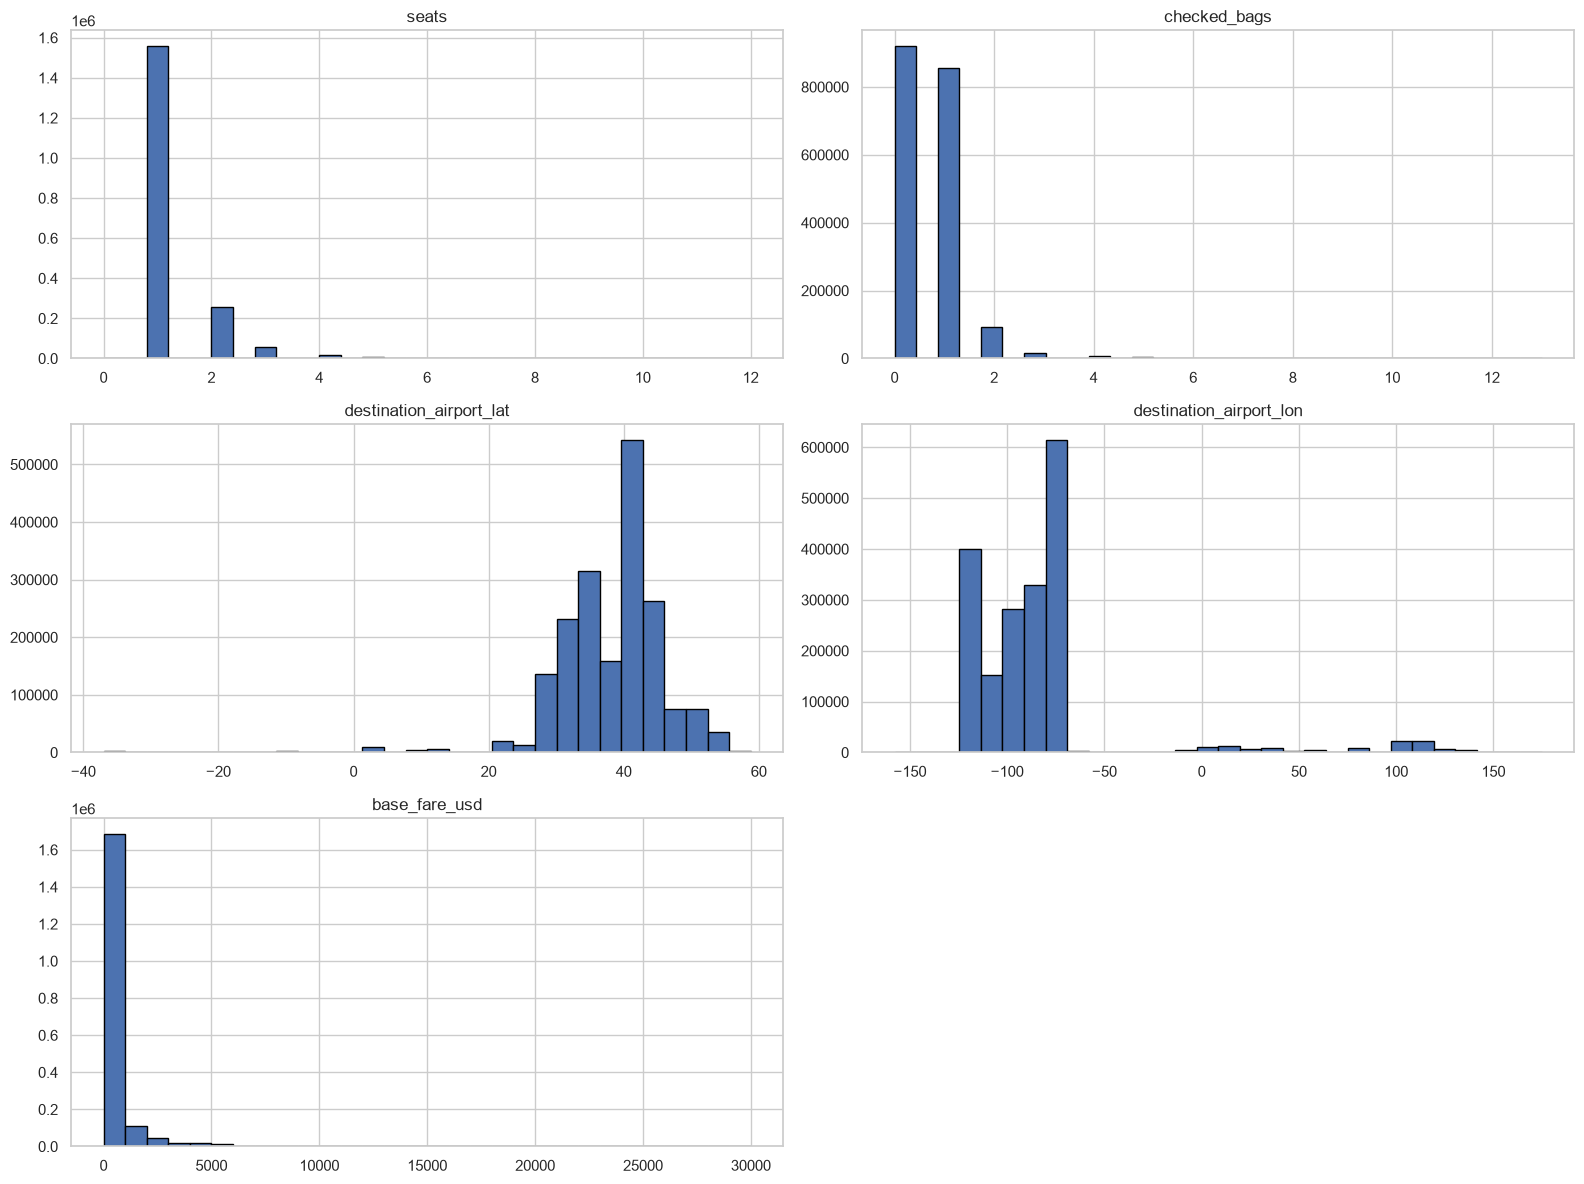

In [70]:
# Verteilung numerischer Variablen
flights.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

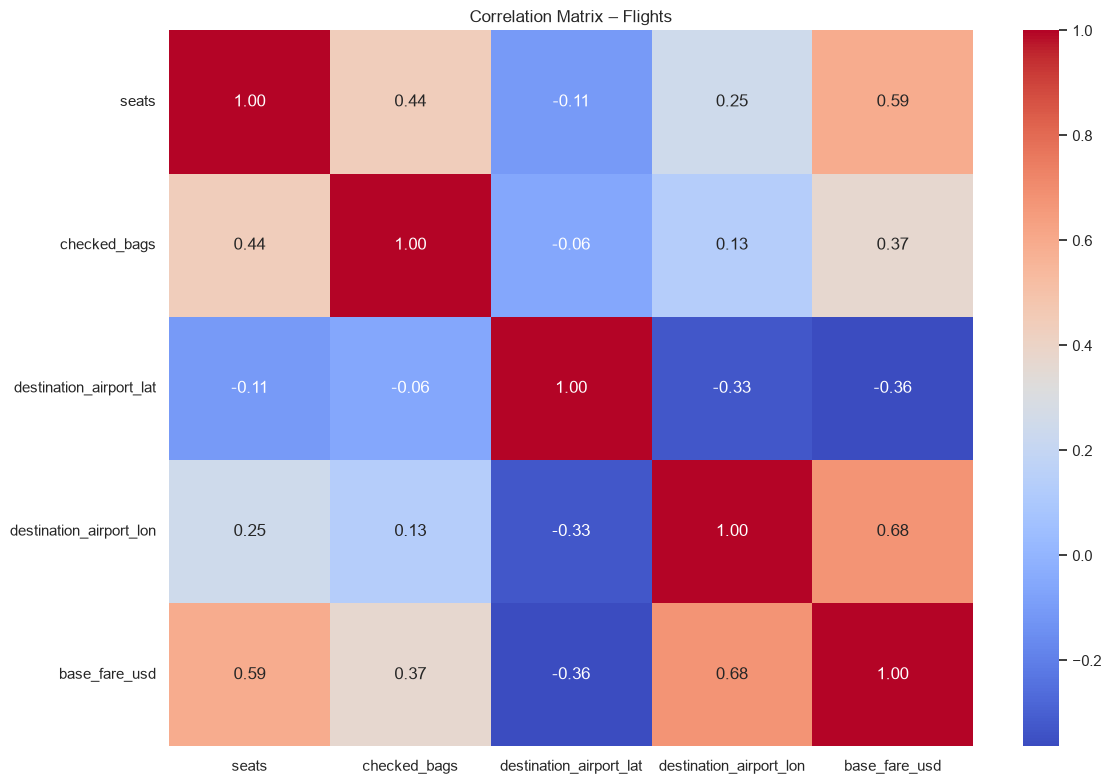

In [71]:
# Nur numerische Spalten berücksichtigen
numeric_flights = flights.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_flights.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix – Flights")
plt.tight_layout()
plt.show()


In [72]:
# Alle Spalten mit maximal 2 unterschiedlichen Werten identifizieren
binary_columns = [
    col for col in flights.columns
    if flights[col].nunique(dropna=True) == 2
]

print("Columns with exactly 2 distinct values:")
print(binary_columns)

# Tatsächliche Werte je Spalte anzeigen
for col in binary_columns:
    print(f"\nColumn: {col}")
    print(flights[col].value_counts(dropna=False))


Columns with exactly 2 distinct values:
['return_flight_booked']

Column: return_flight_booked
return_flight_booked
t    1812304
f      88734
Name: count, dtype: int64


In [73]:

# ============================================================
# TRAVELTIDE – FLIGHTS: BOOLEAN CONVERSION
# ============================================================

from pathlib import Path

# Boolean-Spalten definieren
boolean_columns = [
    "return_flight_booked"
]

# ------------------------------------------------------------
# 1. Prüfen, ob alle angegebenen Spalten vorhanden sind
# ------------------------------------------------------------

missing_columns = [
    col for col in boolean_columns
    if col not in flights.columns
]

if missing_columns:
    raise KeyError(
        f"Missing columns in flights: {missing_columns}"
    )

# ------------------------------------------------------------
# 2. Fehlende Werte vor der Konvertierung prüfen
# ------------------------------------------------------------

missing_values = flights[boolean_columns].isna().sum()

print("Missing values before conversion:")
print(missing_values)

if missing_values.sum() == 0:

    # --------------------------------------------------------
    # 3. Boolean-Konvertierung durchführen
    # --------------------------------------------------------

    for col in boolean_columns:

        values = (
            flights[col]
            .astype("string")
            .str.strip()
            .str.lower()
        )

        # Unerwartete Werte identifizieren
        unexpected = values[~values.isin(["f", "t"])]

        if not unexpected.empty:
            raise ValueError(
                f"Unexpected values in column '{col}': "
                f"{unexpected.unique().tolist()}"
            )

        # f / t in False / True umwandeln
        flights[col] = values.map({
            "f": False,
            "t": True
        })

    print("\nBoolean conversion successful.")

    # --------------------------------------------------------
    # 4. Bereinigten Datensatz speichern
    # --------------------------------------------------------

    # CSV speichern
    flights.to_csv(TARGET_FILE, index=False)

    print("\nSaved successfully to:")
    print(TARGET_FILE)

else:

    # --------------------------------------------------------
    # 5. Konvertierung bei fehlenden Werten abbrechen
    # --------------------------------------------------------

    print(
        "\nConversion cancelled: NaN values were found. "
        "Please investigate them first."
    )


Missing values before conversion:
return_flight_booked    0
dtype: int64

Boolean conversion successful.

Saved successfully to:
D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\02_inspection\insp_flights.csv


In [74]:
# Anzahl True und False für alle Binary Columns ermitteln
boolean_counts = pd.DataFrame({
    "True": (flights[binary_columns] == True).sum(),
    "False": (flights[binary_columns] == False).sum()
})

display(boolean_counts)

,True,False
return_flight_booked,1812304,88734
